# Exploratory shape analysis (before the final SSM)

A fast, throwaway-quality first pass over the **healthy whole-gland** cohort: clean masks →
extract surfaces → ShapeWorks particle correspondence → Procrustes + PCA → inspect.
The question we want answered: does the cohort produce a sensible low-dimensional shape
space, and does it separate by source dataset / acquisition site or gland size?

**Setup**
- `pip install -e ".[dev,analysis]"` (or `pip install -r requirements-dev.txt`).
- **ShapeWorks is not pip-installable.** Install it from
  https://sciinstitute.github.io/ShapeWorks/ and run *this notebook from the ShapeWorks
  environment* so `import shapeworks` works and the `shapeworks` CLI is on PATH. Every step
  except the correspondence cell works without it.
- Point `SAML_DIR` / `PROSTATE158_DIR` at the two dataset roots. SAML is the multi-center
  prostate set (BIDMC, BMC, HK, I2CVB, RUNMC, UCL — the last two overlap with PROMISE12);
  we use it in place of PROMISE12 so each acquisition site becomes its own labelled source.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from shape_modeling.io.reader import discover_cases
from shape_modeling.analysis import (
    build_cohort, clean_mask, extract_surface, CleanConfig,
    gpa, build_ssm, mode_shape,
)

# --- edit these two paths ---
SAML_DIR = Path("../SAML")              # multi-center prostate set (incl. PROMISE12 centers)
PROSTATE158_DIR = Path("../Prostate158")

# Particle count drives a per-resolution work dir so runs never clobber each other:
# 512 -> ../shapeworks_work_saml_512p, 2048 -> ../shapeworks_work_saml_2048p. Everything
# downstream (cache, groomed/, mode_shapes/, mean_shape.ply) lands under WORK_DIR, so flipping
# NUM_PARTICLES gives the new run its own folder and switching back reuses the old cache.
NUM_PARTICLES = 1024
WORK_DIR = Path(f"../shapeworks_work_saml_{NUM_PARTICLES}p")

## 1. Load both datasets and build the healthy cohort

`discover_cases` is run per dataset so the **source** label is unambiguous. SAML bundles
several acquisition sites under one root; `discover_cases` namespaces the case ids by
sub-folder (e.g. `BIDMC/Case00`) so cases from different sites don't collide on disk during
the ShapeWorks step. We then relabel each SAML entry's source to its **center**, so the mode
scatter is coloured per acquisition site — the whole point of swapping in SAML. `build_cohort`
keeps only cases with **no cancer segmentation** and attaches the source and gland volume.

In [2]:
ds_saml = discover_cases(SAML_DIR, default_mri_type="T2W")
ds_prostate = discover_cases(PROSTATE158_DIR, default_mri_type="T2W")
print("SAML:", len(ds_saml), "cases |", "Prostate158:", len(ds_prostate), "cases")

cohort = build_cohort({"SAML": ds_saml, "Prostate158": ds_prostate})

# Drop acquisition sites whose whole-gland masks are unusable. I2CVB's segmentations have a flat
# (planar) truncation -- the gland is cut off by the annotation crop rather than following the real
# boundary -- so pooling them would inject a spurious flat-face shape mode. Exclude the whole site.
# SAML case ids are namespaced by sub-folder ("I2CVB/Case00"); Prostate158 ids ("022") have no "/"
# so split("/")[0] is the id itself and never matches a site name -> only SAML sites are filtered.
EXCLUDE_SITES = {"I2CVB"}
dropped = [e.case_id for e in cohort if e.case_id.split("/")[0] in EXCLUDE_SITES]
cohort = [e for e in cohort if e.case_id.split("/")[0] not in EXCLUDE_SITES]
if dropped:
    print(f"excluded {len(dropped)} cases from sites {sorted(EXCLUDE_SITES)}: "
          f"{dropped[0]} ... {dropped[-1]}")

# SAML case ids are namespaced by center ("BIDMC/Case00"); relabel each entry's source to its
# center so each acquisition site is coloured separately in the scatter below.
for e in cohort:
    if e.source == "SAML":
        e.source = "SAML:" + e.case_id.split("/")[0]

print(f"\nHealthy cohort: {len(cohort)} cases")
from collections import Counter
for s, n in sorted(Counter(e.source for e in cohort).items()):
    print(f"  {s:<18}{n:>4}")

print(f"\n{'case':<24}{'source':<18}{'volume_cm3':>10}")
print("-" * 52)
for e in cohort:
    print(f"{e.case_id:<24}{e.source:<18}{e.volume_cm3:>10.1f}")

sources = np.array([e.source for e in cohort])
volumes = np.array([e.volume_cm3 for e in cohort])

SAML: 116 cases | Prostate158: 139 cases
excluded 19 cases from sites ['I2CVB']: I2CVB/Case00 ... I2CVB/Case18

Healthy cohort: 153 cases
  Prostate158         56
  SAML:BIDMC          12
  SAML:BMC            30
  SAML:HK             12
  SAML:RUNMC          30
  SAML:UCL            13

case                    source            volume_cm3
----------------------------------------------------
022                     Prostate158             70.3
023                     Prostate158             52.8
024                     Prostate158             88.2
026                     Prostate158             22.8
028                     Prostate158             25.7
034                     Prostate158            175.4
037                     Prostate158             99.2
040                     Prostate158             67.8
042                     Prostate158             64.0
044                     Prostate158             51.8
047                     Prostate158             35.3
049                   

## 2. Clean masks and extract surfaces

Keep the largest connected component, fill interior holes, and triangulate with marching
cubes (vertices placed in physical mm). Surfaces here are for inspection — the
correspondence step feeds the *segmentations* to ShapeWorks.

case                   raw vox  clean vox   verts   faces     bbox mm (x,y,z)
-----------------------------------------------------------------------------
022                     145241     144165   34952   69900          (50,59,64)
023                     109017     104860   27168   54332          (55,40,42)
024                     182171     181180   41708   83412          (64,53,57)


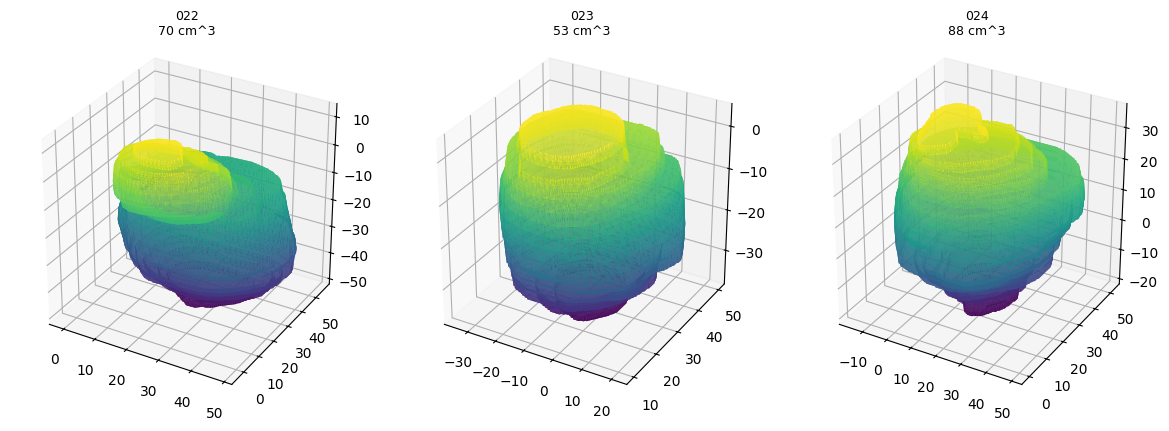

In [3]:
clean_cfg = CleanConfig(keep_largest=True, fill_holes=True, smooth_sigma=1.0)

# Render the first few glands as a sanity check, and report the mesh/volume numbers per shape.
n_show = min(3, len(cohort))
fig = plt.figure(figsize=(4 * n_show, 4))
print(f"{'case':<20}{'raw vox':>10}{'clean vox':>11}{'verts':>8}{'faces':>8}{'bbox mm (x,y,z)':>20}")
print("-" * 77)
for i in range(n_show):
    e = cohort[i]
    cleaned = clean_mask(e.organ.array, clean_cfg)
    surf = extract_surface(cleaned, e.organ)
    ext = surf.verts.max(0) - surf.verts.min(0)
    print(f"{e.case_id:<20}{int((e.organ.array > 0).sum()):>10}{int(cleaned.sum()):>11}"
          f"{len(surf.verts):>8}{len(surf.faces):>8}"
          f"{f'({ext[0]:.0f},{ext[1]:.0f},{ext[2]:.0f})':>20}")
    ax = fig.add_subplot(1, n_show, i + 1, projection="3d")
    ax.plot_trisurf(surf.verts[:, 0], surf.verts[:, 1], surf.faces, surf.verts[:, 2],
                    cmap="viridis", linewidth=0, antialiased=True)
    ax.set_title(f"{e.case_id}\n{e.volume_cm3:.0f} cm^3", fontsize=9)
    ax.set_box_aspect((1, 1, 1))
plt.tight_layout(); plt.show()

## 3. Particle correspondence (ShapeWorks)

Grooms each whole-gland mask (antialias → isotropic resample → distance transform) and runs
the particle optimizer. The result is **cached** in `WORK_DIR/particles.npz`, so re-running
this cell is instant once the optimizer has run once.

> Requires ShapeWorks. If `import shapeworks` fails, see the setup note at the top.

In [4]:
from shape_modeling.analysis import run_shapeworks, ShapeWorksConfig
from shape_modeling.analysis.correspondence import ParticleSystem, particle_spread_ratio

# use_cache=True: WORK_DIR is per-particle-count, so the cache can't mix resolutions.
sw_cfg = ShapeWorksConfig(num_particles=NUM_PARTICLES, iterations=1000, work_dir=WORK_DIR, use_cache=True)

# Self-clean a stale/degenerate cache (e.g. the pre-grooming-fix scattered run) so the fixed
# grooming re-optimizes; a healthy cache (spread ratio ~1) is kept, so reruns stay instant.
cache = WORK_DIR / "particles.npz"
if cache.exists() and sw_cfg.max_spread_ratio is not None:
    old = ParticleSystem.load(cache)
    if old.case_ids == [e.case_id for e in cohort] and \
            particle_spread_ratio(old, cohort) > sw_cfg.max_spread_ratio:
        cache.unlink()
        print("dropped pre-fix scattered cache -> will re-groom + re-optimize")

system = run_shapeworks(cohort, sw_cfg)        # (S, M, 3); cached after the first good run
print("particles:", system.particles.shape, "for", len(system.case_ids), "subjects")
print(f"spread ratio: {particle_spread_ratio(system, cohort):.2f}  (healthy ~1.0-1.3)")
assert system.case_ids == [e.case_id for e in cohort]   # rows align with metadata

particles: (153, 1024, 3) for 153 subjects
spread ratio: 0.97  (healthy ~1.0-1.3)


### Diagnostic: is the cross-dataset alignment actually working?

Opening the groomed files in ShapeWorks Studio and seeing each gland sit in a **different part
of its box** is *expected* and **not** an alignment failure: the last grooming step
`fitRegion`-crops every subject to its **own** gland bounding box, so each groomed image has its
own grid, origin and extent. Where a gland sits *within its own crop box* says nothing about
whether the shapes co-locate in **world space** — which is the only thing the COM-centre + ICP
alignment touches (it runs *before* the crop).

So judge alignment in world coordinates, two ways:

1. **Groomed-gland world COMs should cluster.** COM-centring puts each shape at *its own grid
   centre* (a different physical point per subject, since image sizes differ); the ICP-to-reference
   step is what actually pulls them together. Tightly clustered COMs (std a few mm, no per-source
   offset) ⇒ ICP converged. Tens of mm of scatter, or a systematic per-dataset shift ⇒ a cohort is
   mis-registered.
2. **The optimizer's `*_world.particles` should overlap into one blob.** These are the
   Procrustes-aligned particles the SSM is actually built from — the real test of correspondence.

Reads straight off disk (no `system`/`cohort` needed), so point `DIAG_WORK_DIR` at whichever run
you opened in Studio.

153 groomed glands across 6 sources
world COM std per axis [x y z] mm: [2.08 5.71 7.74]  | bounding gap mm: [18.1 22.8 33.2]

source           n       mean COM (x,y,z) mm
BIDMC           12       [ 18.5  15.7 -17.7]
BMC             30       [ 18.4  18.  -19.9]
HK              12       [ 19.   17.3 -21.8]
Prostate158     56       [ 19.1  21.1 -23.5]
RUNMC           30       [ 19.4  21.3 -23.2]
UCL             13       [ 18.7  23.  -27. ]


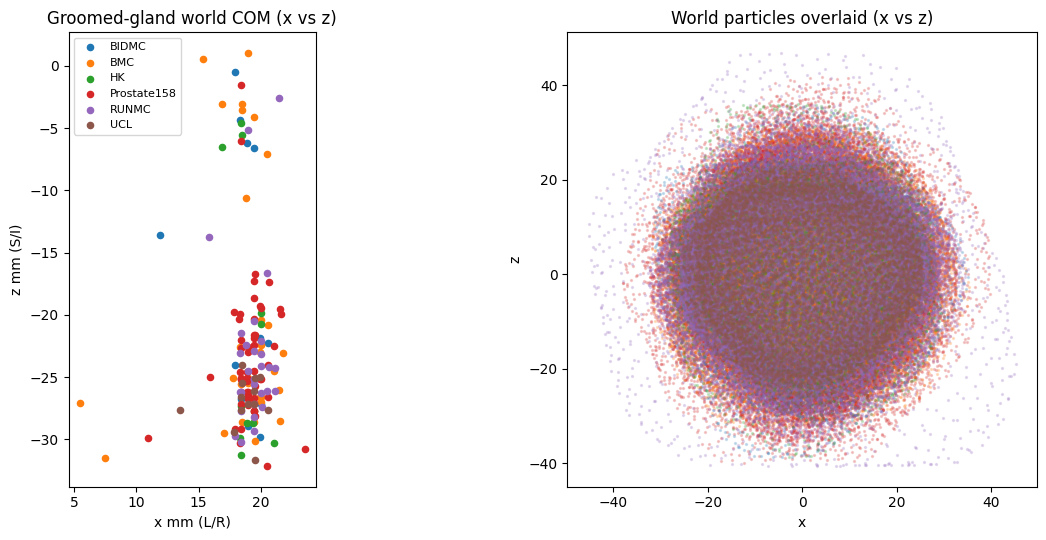


READ IT: left = a tight blob with no per-source separation (COM std a few mm), and right = a single overlapping cloud  =>  alignment is fine and the Studio 'different box' look is just the per-subject crop. A per-source shift on the left, or separated clouds on the right, means a dataset is mis-registered (or this is a stale pre-grooming-fix run -- re-optimize).


In [17]:
import itertools

import SimpleITK as sitk

DIAG_WORK_DIR = Path("../shapeworks_work_saml_1024p")   # <- the run you opened in Studio

def _source(stem):  # SAML/PROMISE12 cases are "<SITE>__CaseNN"; Prostate158 are bare numbers
    return stem.split("__")[0] if "__" in stem else "Prostate158"

# (1) world-space centre of mass of each groomed gland --------------------------------------------
stems, coms = [], []
for p in sorted((DIAG_WORK_DIR / "groomed").glob("*_DT.nrrd")):
    dt = sitk.ReadImage(str(p))
    idx = np.argwhere(sitk.GetArrayFromImage(dt) <= 0)            # DT <= 0 is interior, (z, y, x)
    coms.append(dt.TransformContinuousIndexToPhysicalPoint(idx.mean(0)[::-1].tolist()))  # -> (x, y, z)
    stems.append(p.name[: -len("_DT.nrrd")])
coms = np.asarray(coms)
srcs = np.array([_source(s) for s in stems])
src_names = sorted(set(srcs))

print(f"{len(stems)} groomed glands across {len(src_names)} sources")
print("world COM std per axis [x y z] mm:", np.round(coms.std(0), 2),
      " | bounding gap mm:", np.round(np.ptp(coms, axis=0), 1))
print(f"\n{'source':<14}{'n':>4}{'mean COM (x,y,z) mm':>26}")
for s in src_names:
    m = srcs == s
    print(f"{s:<14}{int(m.sum()):>4}{str(np.round(coms[m].mean(0), 1)):>26}")

# (2) optimizer world particles (Procrustes-aligned) ----------------------------------------------
pdir = DIAG_WORK_DIR / "shape_model_particles"
world = {f.name[: -len("_DT_world.particles")]: np.loadtxt(f)
         for f in sorted(pdir.glob("*_DT_world.particles"))}

# --- plot: COMs (left) and overlaid world particles (right), coloured by source ------------------
colors = dict(zip(src_names, itertools.cycle(plt.cm.tab10.colors)))
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5.5))
for s in src_names:
    m = srcs == s
    axL.scatter(coms[m, 0], coms[m, 2], s=20, color=colors[s], label=s)   # x vs z = L/R vs S/I
axL.set(title="Groomed-gland world COM (x vs z)", xlabel="x mm (L/R)", ylabel="z mm (S/I)")
axL.set_aspect("equal"); axL.legend(fontsize=8)
for stem, pts in world.items():
    axR.scatter(pts[:, 0], pts[:, 2], s=2, alpha=0.2, color=colors[_source(stem)])
axR.set(title="World particles overlaid (x vs z)", xlabel="x", ylabel="z"); axR.set_aspect("equal")
plt.tight_layout(); plt.show()

print("\nREAD IT: left = a tight blob with no per-source separation (COM std a few mm), and right = "
      "a single overlapping cloud  =>  alignment is fine and the Studio 'different box' look is just "
      "the per-subject crop. A per-source shift on the left, or separated clouds on the right, means "
      "a dataset is mis-registered (or this is a stale pre-grooming-fix run -- re-optimize).")

## 4. Procrustes align + PCA

Generalized Procrustes removes pose and scale; PCA over the aligned particles gives the mean
shape, principal modes, eigenvalues, and per-subject scores.

In [ ]:
aligned, mean_shape = gpa(system.particles, scale=False)
model = build_ssm(aligned)
print(f"{model.n_modes} modes over {model.n_points} points")
print("variance explained by first 5 modes:",
      np.round(model.explained_variance_ratio[:5], 3))

152 modes over 1024 points
variance explained by first 5 modes: [0.259 0.136 0.117 0.106 0.082]


## 5. Inspect

### Eigenvalue decay (scree) + cumulative variance
How many modes actually matter?

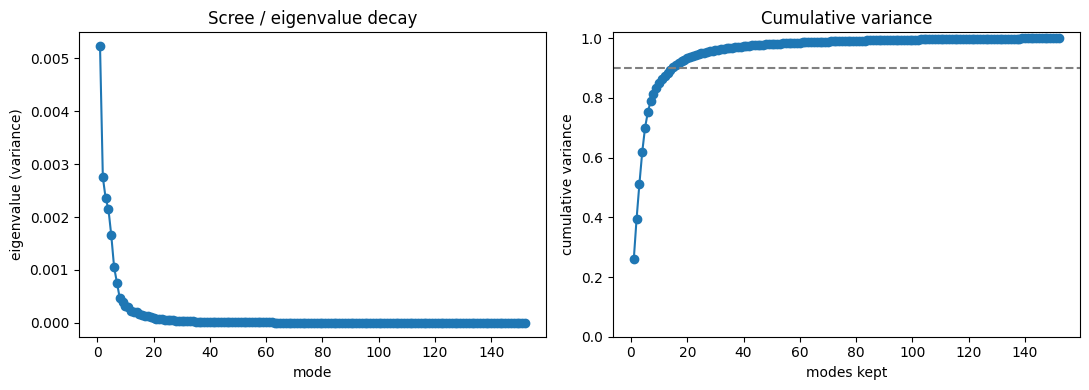

mode      eigenvalue   var ratio  cumulative
--------------------------------------------
1           0.005227       0.259       0.259
2            0.00275       0.136       0.395
3           0.002353       0.117       0.512
4           0.002143       0.106       0.618
5           0.001652       0.082       0.700
6           0.001053       0.052       0.752
7           0.000759       0.038       0.790
8           0.000471       0.023       0.813
modes to reach 90% variance: 15 / 152
modes to reach 95% variance: 26 / 152
modes to reach 99% variance: 73 / 152


In [7]:
k = model.n_modes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(np.arange(1, k + 1), model.eigenvalues, "o-")
ax1.set(xlabel="mode", ylabel="eigenvalue (variance)", title="Scree / eigenvalue decay")
ax2.plot(np.arange(1, k + 1), np.cumsum(model.explained_variance_ratio), "o-")
ax2.axhline(0.9, ls="--", c="grey"); ax2.set_ylim(0, 1.02)
ax2.set(xlabel="modes kept", ylabel="cumulative variance", title="Cumulative variance")
plt.tight_layout(); plt.show()

cum = np.cumsum(model.explained_variance_ratio)
print(f"{'mode':<6}{'eigenvalue':>14}{'var ratio':>12}{'cumulative':>12}")
print("-" * 44)
for i in range(min(8, k)):
    print(f"{i+1:<6}{model.eigenvalues[i]:>14.4g}{model.explained_variance_ratio[i]:>12.3f}{cum[i]:>12.3f}")
for thr in (0.90, 0.95, 0.99):
    print(f"modes to reach {thr:.0%} variance: {int(np.searchsorted(cum, thr) + 1)} / {k}")

### Mode scatter, coloured by source dataset and by gland volume
Does shape separate by where the scan came from, or just track size?

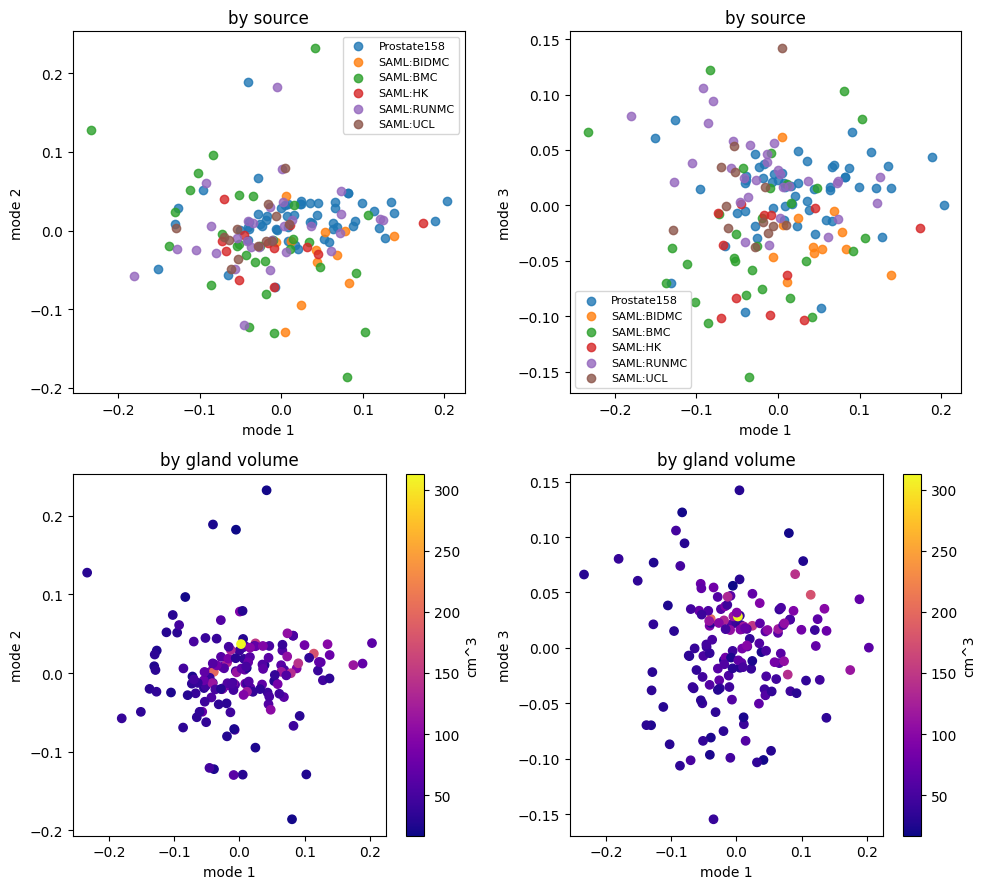

mean score by source
source              n       m1       m2       m3
------------------------------------------------
Prostate158        56    0.023    0.016    0.011
SAML:BIDMC         12    0.046   -0.032   -0.028
SAML:BMC           30   -0.027   -0.011   -0.023
SAML:HK            12   -0.007   -0.018   -0.044
SAML:RUNMC         30   -0.016    0.002    0.028
SAML:UCL           13   -0.038   -0.001    0.009

mode vs gland volume (Pearson r, p):
  mode 1: r=+0.271  p=0.00071
  mode 2: r=+0.090  p=0.27
  mode 3: r=+0.230  p=0.0043


In [8]:
from scipy import stats

src_names = sorted(set(sources))
src_to_int = {s: i for i, s in enumerate(src_names)}
src_idx = np.array([src_to_int[s] for s in sources])

pairs = [(0, 1), (0, 2)]
fig, axes = plt.subplots(2, len(pairs), figsize=(5 * len(pairs), 9))
for col, (a, b) in enumerate(pairs):
    # by source
    ax = axes[0, col]
    for s in src_names:
        m = sources == s
        ax.scatter(model.scores[m, a], model.scores[m, b], label=s, alpha=0.8)
    ax.set(xlabel=f"mode {a+1}", ylabel=f"mode {b+1}", title="by source")
    ax.legend(fontsize=8)
    # by volume
    ax = axes[1, col]
    sc = ax.scatter(model.scores[:, a], model.scores[:, b], c=volumes, cmap="plasma")
    ax.set(xlabel=f"mode {a+1}", ylabel=f"mode {b+1}", title="by gland volume")
    fig.colorbar(sc, ax=ax, label="cm^3")
plt.tight_layout(); plt.show()

modes_shown = sorted({m for pair in pairs for m in pair})
# mean score per source for the displayed modes
hdr = "".join(f"{'m' + str(m + 1):>9}" for m in modes_shown)
print(f"mean score by source\n{'source':<16}{'n':>5}{hdr}")
print("-" * (21 + 9 * len(modes_shown)))
for s in src_names:
    msk = sources == s
    row = "".join(f"{model.scores[msk, m].mean():>9.3f}" for m in modes_shown)
    print(f"{s:<16}{int(msk.sum()):>5}{row}")
# does each mode track gland size?
print("\nmode vs gland volume (Pearson r, p):")
for m in modes_shown:
    r, p = stats.pearsonr(model.scores[:, m], volumes)
    print(f"  mode {m + 1}: r={r:+.3f}  p={p:.2g}")

### Pairplot of the first modes

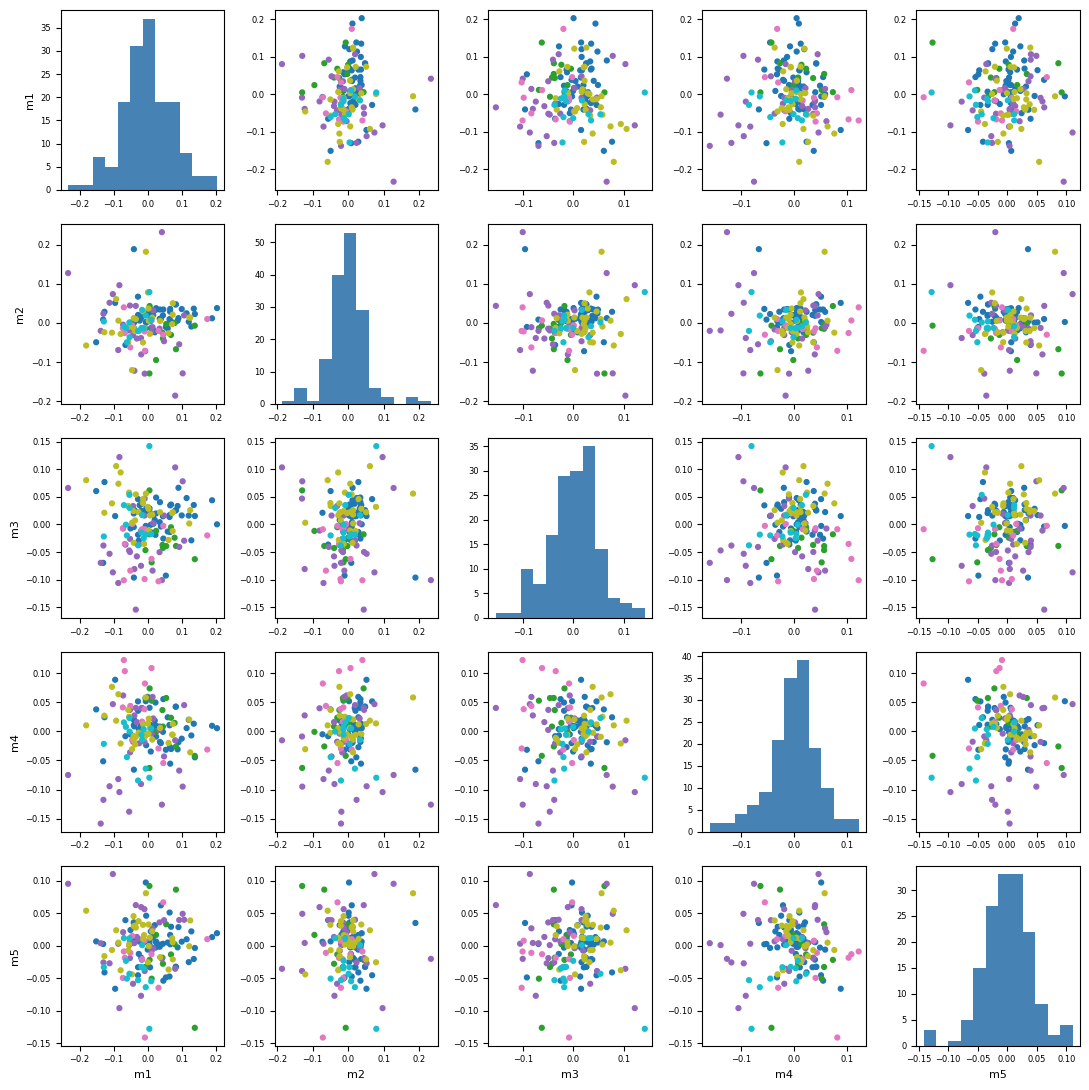

mode       mean      std      min      max     skew
---------------------------------------------------
1         0.000    0.072   -0.233    0.203    0.034
2        -0.000    0.052   -0.186    0.232    0.493
3         0.000    0.048   -0.154    0.142   -0.210
4         0.000    0.046   -0.158    0.122   -0.568
5         0.000    0.041   -0.141    0.111   -0.343


In [9]:
n_modes_plot = min(5, model.n_modes)
fig, axes = plt.subplots(n_modes_plot, n_modes_plot, figsize=(2.2 * n_modes_plot, 2.2 * n_modes_plot))
for i in range(n_modes_plot):
    for j in range(n_modes_plot):
        ax = axes[i, j]
        if i == j:
            ax.hist(model.scores[:, i], bins=12, color="steelblue")
        else:
            ax.scatter(model.scores[:, j], model.scores[:, i], c=src_idx, cmap="tab10", s=12)
        if i == n_modes_plot - 1:
            ax.set_xlabel(f"m{j+1}", fontsize=8)
        if j == 0:
            ax.set_ylabel(f"m{i+1}", fontsize=8)
        ax.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

# per-mode score distribution (std should track sqrt(eigenvalue); skew flags asymmetry/outliers)
print(f"{'mode':<6}{'mean':>9}{'std':>9}{'min':>9}{'max':>9}{'skew':>9}")
print("-" * 51)
for i in range(n_modes_plot):
    col = model.scores[:, i]
    print(f"{i+1:<6}{col.mean():>9.3f}{col.std():>9.3f}{col.min():>9.3f}{col.max():>9.3f}{stats.skew(col):>9.3f}")

### Clustering sanity-check: k-means + silhouette
Is there real structure in the score space, or one blob? (Indicative only.)

k=2: silhouette=0.209
k=3: silhouette=0.195
k=4: silhouette=0.198
k=5: silhouette=0.194
k=6: silhouette=0.177


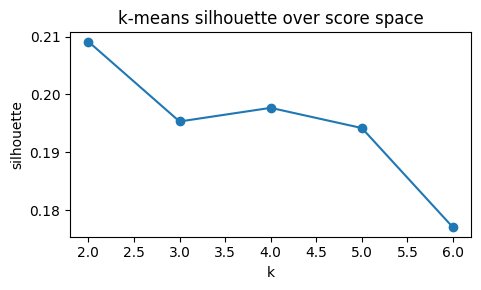

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = model.scores[:, : min(5, model.n_modes)]
ks = range(2, min(7, len(cohort)))
sils = []
for kk in ks:
    labels = KMeans(n_clusters=kk, n_init=10, random_state=0).fit_predict(X)
    sils.append(silhouette_score(X, labels))
for kk, s in zip(ks, sils):
    print(f"k={kk}: silhouette={s:.3f}")
plt.figure(figsize=(5, 3))
plt.plot(list(ks), sils, "o-"); plt.xlabel("k"); plt.ylabel("silhouette")
plt.title("k-means silhouette over score space"); plt.tight_layout(); plt.show()

### Mean shape ± sd along the first modes ("animate and name")

Walk the mean along each mode and **export the deformed surfaces** as PLY meshes:
`shape = mean + c · √eigenvalue · mode` for `c ∈ {−3, −2, 0, +2, +3}`. Using √eigenvalue
scales each step to that mode's natural SD, so ±3 SD spans the realistic range. All meshes
reuse the **mean's convex-hull connectivity**, so vertex *j* is the same point everywhere —
load `mode1_-3sd / _+0sd / _+3sd` together in 3D Slicer or ParaView (or animate `c`) and name
the mode by *where and how* the surface moves: size, elongation, AP/LR flattening, base–apex
asymmetry.

> **Units:** `mode_shape` works on the Procrustes-aligned coordinates, and `gpa(scale=True)`
> normalises every shape to unit Frobenius norm — so these coordinates (and the displacement
> table below) are **normalized, not mm**. That's why the magnitudes are ~0.0x. The shapes
> are still correct *up to a global scale*; only absolute size is gone (by design).

wrote 25 meshes to ../shapeworks_work_saml_1024p/mode_shapes/  (open mode<k>_-3sd/_+0sd/_+3sd together)


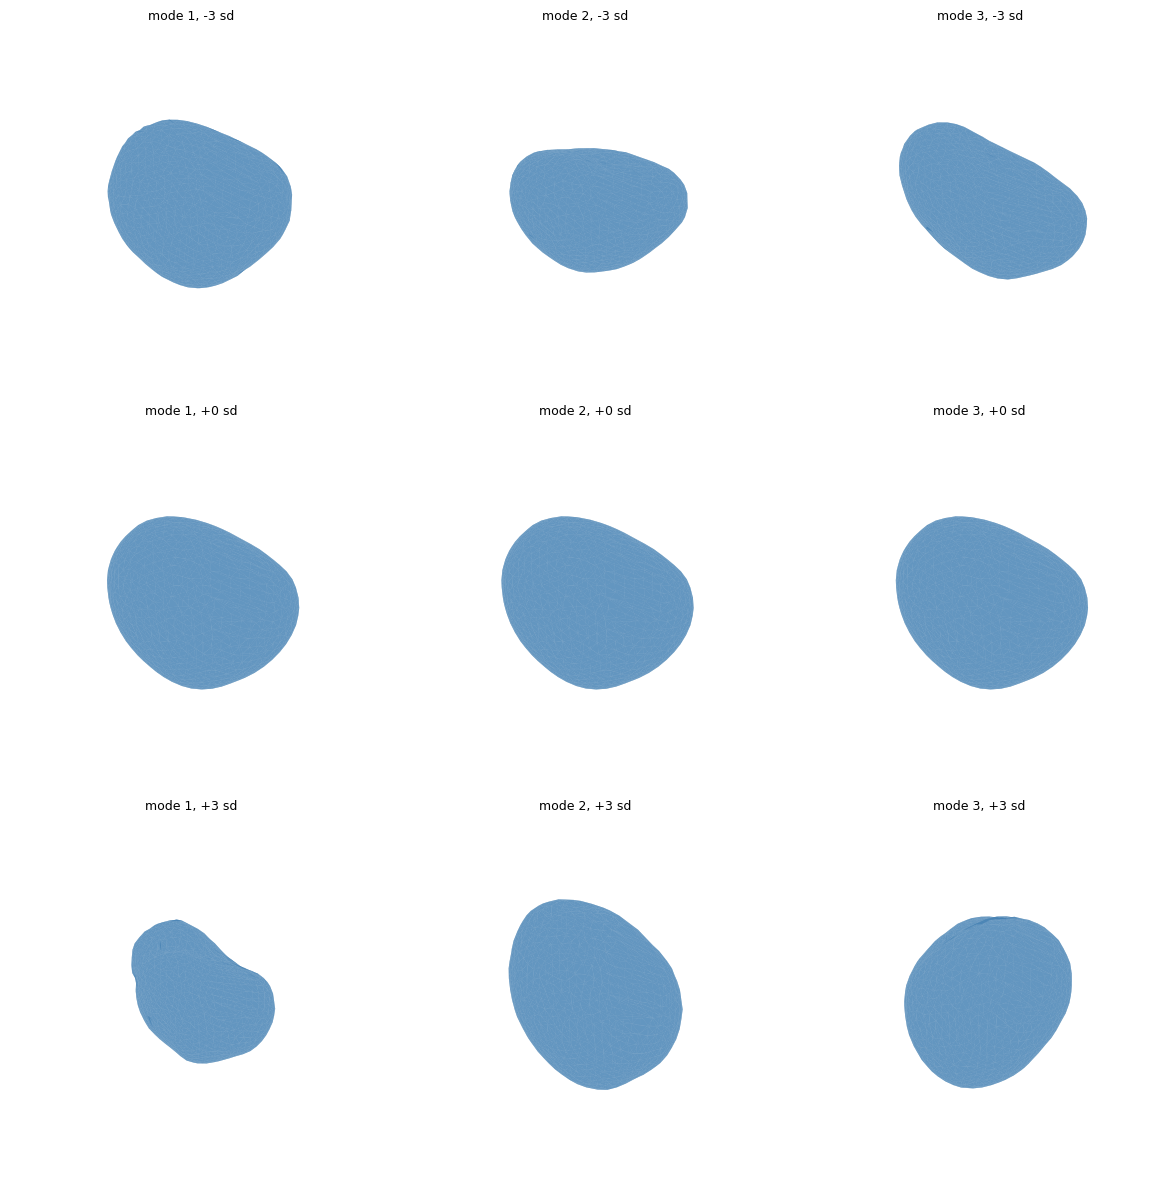


mode    var ratio   RMS disp +2sd   max disp +2sd  (normalized units)
-----------------------------------------------------------------
1           0.259          0.0045          0.0097
2           0.136          0.0033          0.0060
3           0.117          0.0030          0.0070


In [11]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from shape_modeling.analysis import export_mode_shapes, hull_surface

# 1. Export deformed surfaces for the first 5 modes at -3/-2/0/+2/+3 sd -> PLY for Slicer/ParaView.
ply_dir = WORK_DIR / "mode_shapes"
paths = export_mode_shapes(model, ply_dir, n_modes=min(5, model.n_modes))
print(f"wrote {len(paths)} meshes to {ply_dir}/  (open mode<k>_-3sd/_+0sd/_+3sd together)")

# 2. Inline preview: render the actual surface (mean hull faces, reused across the sweep).
faces = hull_surface(model.mean).faces
n_modes_viz = min(3, model.n_modes)
sds_viz = (-3.0, 0.0, 3.0)
fig = plt.figure(figsize=(4 * n_modes_viz, 4 * len(sds_viz)))
for row, sd in enumerate(sds_viz):
    for col in range(n_modes_viz):
        pts = mode_shape(model, col, sd)
        ax = fig.add_subplot(len(sds_viz), n_modes_viz, row * n_modes_viz + col + 1, projection="3d")
        mesh = Poly3DCollection(pts[faces], alpha=0.6, facecolor="steelblue", edgecolor="none")
        ax.add_collection3d(mesh)
        lim = np.abs(pts).max() * 1.05
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim))
        ax.set_title(f"mode {col+1}, {sd:+.0f} sd", fontsize=9)
        ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
plt.tight_layout(); plt.show()

# 3. How much does each mode move the surface? Per-particle displacement of +2 sd vs the mean.
#    NOTE: normalized units (gpa scale=True), NOT mm -- see the units note above.
mean_pts = mode_shape(model, 0, 0.0)   # sd=0 -> the mean shape (mode index irrelevant)
print(f"\n{'mode':<6}{'var ratio':>11}{'RMS disp +2sd':>16}{'max disp +2sd':>16}  (normalized units)")
print("-" * 65)
for m in range(n_modes_viz):
    disp = np.linalg.norm(mode_shape(model, m, 2.0) - mean_pts, axis=1)
    print(f"{m+1:<6}{model.explained_variance_ratio[m]:>11.3f}"
          f"{np.sqrt((disp**2).mean()):>16.4f}{disp.max():>16.4f}")


### Save the mean shape (warped real surface — not a convex hull)

Particles carry no faces, so to mesh the mean we have to get connectivity from somewhere.
A **convex hull** of the mean cloud is wrong for an organ: it keeps only the extreme points
and bridges every concavity (base notch, apex taper) → a faceted balloon. Instead we borrow
faces from a **real** surface: take the most "average" subject's groomed surface (watertight,
concave, full-resolution) and **thin-plate-spline warp** it so its particles land on the model
mean (`warp_surface`). Detail and concavities survive, and the result stays in the model's
**normalized GPA frame**, so it still overlays on the `mode<k>_+0sd.ply` files.

The reference subject's `*_local.particles` are used because they live in the **same frame** as
its groomed distance-transform surface (`*_world.particles` are Procrustes-rotated to the common
frame that builds `model.mean`).

In [12]:
import SimpleITK as sitk
from skimage import measure

from shape_modeling.analysis import Surface, save_ply, warp_surface

# Reference subject = the one whose (world) particles are closest to the mean -> most "average".
mean_world = system.particles.mean(0)
ref_i = int(np.argmin(np.linalg.norm(system.particles - mean_world, axis=(1, 2))))
ref_id = system.case_ids[ref_i]
stem = ref_id.replace("/", "__").replace("\\", "__")   # same sanitisation as the ShapeWorks run

# Its groomed surface: marching cubes at the 0 level-set of the distance transform, mapped to
# the DT's physical frame (the frame the *_local.particles live in).
dt = sitk.ReadImage(str(WORK_DIR / "groomed" / f"{stem}_DT.nrrd"))
vz, faces, *_ = measure.marching_cubes(sitk.GetArrayFromImage(dt).astype(np.float32), level=0.0)
ref_verts = np.array(  # marching cubes returns (z,y,x); SimpleITK indexes (x,y,z)
    [dt.TransformContinuousIndexToPhysicalPoint(tuple(map(float, p))) for p in vz[:, ::-1]]
)
ref_mesh = Surface(verts=ref_verts, faces=faces.astype(np.int64))
ref_local = np.loadtxt(next(WORK_DIR.rglob(f"{stem}_DT_local.particles")))

# Warp that real surface onto the model mean (local frame -> normalized GPA frame).
# smoothing > 0 is essential: with smoothing=0 the spline interpolates *exactly* through all
# particles, and ShapeWorks correspondence noise then makes it oscillate between control points
# -> stretched triangles / a bumpy surface. A small relaxation (the mean is itself an average,
# so exact-fit buys nothing) recovers the template's own smoothness. Tuned on the normalized GPA
# frame here (coords ~0.0x); rescale if you ever warp to mm-scale targets.
mean_surf = warp_surface(ref_mesh, ref_local, model.mean, smoothing=1e-2)
mean_path = WORK_DIR / "mean_shape.ply"
save_ply(mean_surf, mean_path)
print(f"wrote {mean_path}: {len(mean_surf.verts)} verts, {len(mean_surf.faces)} faces "
      f"(template subject {ref_id})")

wrote ../shapeworks_work_saml_1024p/mean_shape.ply: 9704 verts, 19404 faces (template subject UCL/Case28)


### Is mode 1 a size mode? (the rigorous check)

Eyeballing the renders names the modes; this confirms the *size* one numerically. `gpa(scale=True)`
already removed scale, so the centroid size of the **aligned** shapes is ~constant — useless to
correlate. Instead correlate each mode's score against the **raw** (pre-Procrustes) centroid size,
and against gland volume. A near-±1 correlation = that mode tracks size. If scale was removed yet
mode 1 *still* correlates with size, that's the interesting case worth noting.

In [13]:
from scipy import stats

from shape_modeling.analysis import centroid_size

raw_size = centroid_size(system.particles)   # pre-GPA centroid size (physical mm)
print(f"raw centroid size: mean {raw_size.mean():.1f}, cv {raw_size.std()/raw_size.mean():.2f}")
print(f"aligned centroid size cv (≈0 by construction): "
      f"{centroid_size(aligned).std()/centroid_size(aligned).mean():.4f}\n")

print(f"{'mode':<6}{'var':>7}{'r vs raw size':>16}{'p':>11}{'r vs volume':>16}{'p':>11}")
print("-" * 67)
for m in range(min(5, model.n_modes)):
    rs, ps = stats.pearsonr(model.scores[:, m], raw_size)
    rv, pv = stats.pearsonr(model.scores[:, m], volumes)
    flag = "  <- size mode" if max(abs(rs), abs(rv)) > 0.7 else ""
    print(f"{m+1:<6}{model.explained_variance_ratio[m]:>7.2f}"
          f"{rs:>+16.3f}{ps:>11.1e}{rv:>+16.3f}{pv:>11.1e}{flag}")


raw centroid size: mean 750.6, cv 0.18
aligned centroid size cv (≈0 by construction): 0.0000

mode      var   r vs raw size          p     r vs volume          p
-------------------------------------------------------------------
1        0.26          +0.360    4.8e-06          +0.271    7.1e-04
2        0.14          +0.071    3.9e-01          +0.090    2.7e-01
3        0.12          +0.223    5.6e-03          +0.230    4.3e-03
4        0.11          +0.085    3.0e-01          +0.057    4.9e-01
5        0.08          +0.145    7.3e-02          +0.163    4.4e-02


### How does size *align* with the PCA components?

The check above is **statistical** — do larger subjects sit at one end of a mode (score vs raw
centroid size). This adds the **geometric** view: pure isotropic growth moves every point radially
out from the centroid, i.e. along the **centred mean shape**. Treat that unit direction as a vector
in the 3·M shape space and take its cosine with each principal component (the components are
orthonormal). `Σ cos²` over all modes is the fraction of the growth direction that lives in the
model's span. If scale was truly removed, no single mode should align strongly and the growth
direction should be smeared thinly across many low-variance modes.

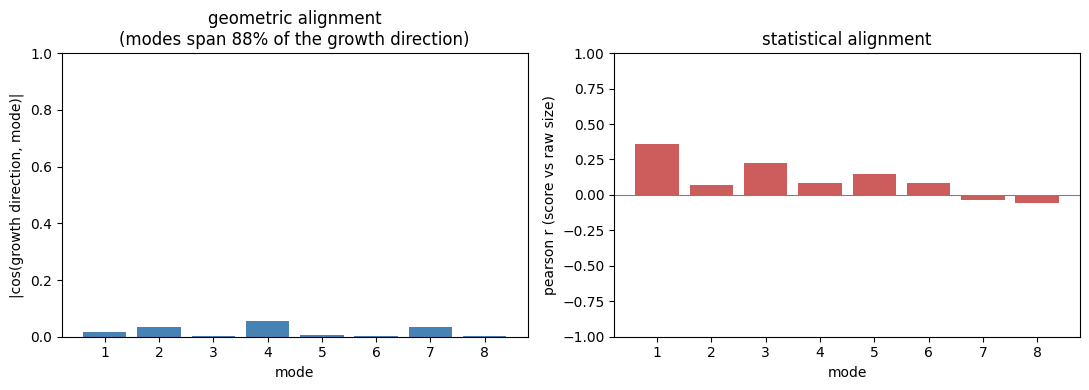

growth direction captured by the 152 modes: 87.9%
most size-aligned mode  (geometric |cos|): mode 20  (0.430)
most size-correlated mode (score vs size): mode 12  (+0.387)
=> no single dominant size mode


In [14]:
# geometric: cosine of each PCA component with the isotropic-growth (size) direction
size_dir = (model.mean - model.mean.mean(0)).reshape(-1)
size_dir = size_dir / np.linalg.norm(size_dir)
cos_align = model.components @ size_dir            # (K,) components are orthonormal rows
captured = float((cos_align ** 2).sum())           # fraction of the size direction in the model span

# statistical: score-vs-raw-size correlation per mode (raw_size from the cell above)
r_size = np.array([stats.pearsonr(model.scores[:, m], raw_size)[0] for m in range(model.n_modes)])

k = min(8, model.n_modes)
x = np.arange(1, k + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(x, np.abs(cos_align[:k]), color="steelblue")
ax1.set(xlabel="mode", ylabel="|cos(growth direction, mode)|", ylim=(0, 1),
        title=f"geometric alignment\n(modes span {captured:.0%} of the growth direction)")
ax2.bar(x, r_size[:k], color="indianred"); ax2.axhline(0, c="grey", lw=0.8)
ax2.set(xlabel="mode", ylabel="pearson r (score vs raw size)", ylim=(-1, 1),
        title="statistical alignment")
plt.tight_layout(); plt.show()

g, s = int(np.argmax(np.abs(cos_align))) + 1, int(np.argmax(np.abs(r_size))) + 1
print(f"growth direction captured by the {model.n_modes} modes: {captured:.1%}")
print(f"most size-aligned mode  (geometric |cos|): mode {g}  ({np.abs(cos_align).max():.3f})")
print(f"most size-correlated mode (score vs size): mode {s}  ({np.abs(r_size).max():+.3f})")
print("=> no single dominant size mode" if max(np.abs(cos_align).max(), np.abs(r_size).max()) < 0.7
      else f"=> mode {g if np.abs(cos_align).max() >= np.abs(r_size).max() else s} carries size")


## 6. Site / acquisition effect (test it, don't eyeball it)

Section 5's source colouring and silhouette are *descriptive*. A site effect is usually a
**continuous shift** along a mode — no clusters, small mean gaps — yet still systematic, and it
can hide past mode 3. So test it directly. Three questions:

1. **Does source structure each mode?** Kruskal–Wallis per mode across the sources (non-parametric
   one-way ANOVA — scores aren't normal and groups are unequal, n = 12–56), with an ε² effect size.
   Run it twice: across **all** sources (acquisition + annotation mixed), and **within SAML only**
   (5 centres, one annotation protocol → isolates pure *acquisition site*). A Mann–Whitney of
   Prostate158 vs SAML gives the dataset/annotation axis on its own. Bonferroni-correct over the
   modes tested.
2. **What is the mechanism?** Re-group SAML by receive coil (endorectal vs surface) and report a
   Welch-t p + η² per mode — a defensible physical cause, not an opaque centre label.
3. **Can we remove it?** *(optional)* a ComBat-style location/scale harmonization, to confirm the
   effect is removable and that biology (gland size) survives it.

> All cancer cases live in Prostate158, so for the **cancer** test the safe route is staying
> *within Prostate158* (one protocol) — no harmonization needed. You only need ComBat to pool the
> healthy basis **across** sites. This section tells you whether that pooling is safe.

In [18]:
from scipy import stats

K = min(10, model.n_modes)                                  # test the leading modes (where var lives)
center = np.array([s.split(":")[-1] for s in sources])      # BIDMC/BMC/HK/RUNMC/UCL/Prostate158
is_saml = np.array([s.startswith("SAML:") for s in sources])

def kruskal_eps2(labels, col):
    """Kruskal-Wallis across the groups in `labels`; returns (p, epsilon^2 effect size in [0,1])."""
    groups = [col[labels == g] for g in np.unique(labels)]
    groups = [g for g in groups if len(g) > 0]
    H, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    return p, H / (n - 1)                                   # epsilon^2 = H/(n-1)

alpha = 0.05 / K                                            # Bonferroni over the K modes tested
print(f"Kruskal-Wallis per mode   (Bonferroni alpha = 0.05/{K} = {alpha:.1e})\n")
print(f"{'mode':<5}{'var%':>6}{'all-src p':>12}{'eps2':>7}{'SAML-only p':>13}{'eps2':>7}"
      f"{'P158-vs-SAML p':>16}")
print("-" * 66)
for m in range(K):
    col = model.scores[:, m]
    p_all, e_all = kruskal_eps2(center, col)                # acquisition + annotation mixed
    p_sml, e_sml = kruskal_eps2(center[is_saml], col[is_saml])   # pure acquisition site (1 protocol)
    _, p_ds = stats.mannwhitneyu(col[~is_saml], col[is_saml])    # dataset/annotation axis
    flag = "  <- source" if p_all < alpha else ""
    print(f"{m+1:<5}{model.explained_variance_ratio[m]*100:>5.1f}{p_all:>12.2e}{e_all:>7.2f}"
          f"{p_sml:>13.2e}{e_sml:>7.2f}{p_ds:>16.2e}{flag}")

print("\nall-src      = any of the sources differ (acquisition + annotation mixed).")
print("SAML-only    = 5 centres under ONE annotation protocol -> isolates ACQUISITION SITE.")
print("P158-vs-SAML = dataset/annotation axis (Prostate158 TZ∪PZ union vs SAML single contour).")
print("eps2: ~0.01 negligible, ~0.06 medium, >0.14 large.  '<- source' = source structures that mode.")

Kruskal-Wallis per mode   (Bonferroni alpha = 0.05/10 = 5.0e-03)

mode   var%   all-src p   eps2  SAML-only p   eps2  P158-vs-SAML p
------------------------------------------------------------------
1     25.9    1.80e-04   0.16     4.82e-03   0.16        1.53e-03  <- source
2     13.6    4.32e-04   0.15     3.01e-01   0.05        2.78e-05  <- source
3     11.7    2.31e-07   0.26     9.01e-06   0.30        9.63e-03  <- source
4     10.6    1.11e-02   0.10     1.47e-02   0.13        3.04e-01
5      8.2    3.54e-03   0.12     3.81e-03   0.16        4.61e-01  <- source
6      5.2    8.74e-02   0.06     5.54e-02   0.10        9.08e-01
7      3.8    7.15e-02   0.07     3.31e-01   0.05        1.95e-02
8      2.3    3.38e-02   0.08     5.16e-02   0.10        1.10e-01
9      1.9    1.64e-01   0.05     2.08e-01   0.06        1.66e-01
10     1.6    5.06e-01   0.03     6.04e-01   0.03        2.65e-01

all-src      = any of the sources differ (acquisition + annotation mixed).
SAML-only    = 5 cen

In [19]:
# Mechanism: receive coil (within SAML only -- Prostate158 has no endorectal arm, so it's left out).
COIL = {"BIDMC": "endorectal", "BMC": "endorectal", "HK": "endorectal",
        "RUNMC": "surface", "UCL": "surface"}            # I2CVB (surface) already excluded from cohort
coil = np.array([COIL.get(c, "n/a") for c in center])
sel = np.isin(coil, ["endorectal", "surface"])

print("Coil mechanism within SAML   (endorectal BIDMC/BMC/HK  vs  surface RUNMC/UCL)\n")
print(f"{'mode':<5}{'endo mean':>11}{'surf mean':>11}{'Welch p':>11}{'eta2':>8}")
print("-" * 46)
for m in range(K):
    col = model.scores[sel, m]; g = coil[sel]
    a, b = col[g == "endorectal"], col[g == "surface"]
    _, p = stats.ttest_ind(a, b, equal_var=False)
    grand = col.mean()
    ss_b = len(a) * (a.mean() - grand) ** 2 + len(b) * (b.mean() - grand) ** 2
    ss_t = ((col - grand) ** 2).sum()
    eta2 = ss_b / ss_t if ss_t > 0 else np.nan
    print(f"{m+1:<5}{a.mean():>+11.3f}{b.mean():>+11.3f}{p:>11.2e}{eta2:>8.3f}")

print("\neta2 = fraction of that mode's (within-SAML) variance explained by coil type.")
print("A mode with large coil eta2 is acquisition-driven, not anatomy -- harmonize before reading biology.")
print("Coil is ONE factor; if 'SAML-only' Kruskal above is significant where coil eta2 is small,")
print("other acquisition factors (field strength, vendor, resolution) are also in play -> harmonize on CENTRE.")

Coil mechanism within SAML   (endorectal BIDMC/BMC/HK  vs  surface RUNMC/UCL)

mode   endo mean  surf mean    Welch p    eta2
----------------------------------------------
1         -0.006     -0.022   2.42e-01   0.014
2         -0.017     +0.001   1.20e-01   0.023
3         -0.029     +0.022   6.27e-07   0.219
4         -0.006     -0.001   6.87e-01   0.001
5         -0.000     -0.004   6.62e-01   0.002
6         -0.000     +0.002   7.80e-01   0.001
7         +0.007     +0.000   1.93e-01   0.016
8         +0.004     -0.001   2.44e-01   0.014
9         -0.005     +0.001   1.08e-01   0.025
10        -0.001     -0.000   9.08e-01   0.000

eta2 = fraction of that mode's (within-SAML) variance explained by coil type.
A mode with large coil eta2 is acquisition-driven, not anatomy -- harmonize before reading biology.
Coil is ONE factor; if 'SAML-only' Kruskal above is significant where coil eta2 is small,
other acquisition factors (field strength, vendor, resolution) are also in play -> harmo

### Optional: harmonize the site effect (ComBat-style location/scale)

Location/scale (L/S) correction is the deterministic core of ComBat: per source, subtract that
source's additive shift and divide out its multiplicative scale on each mode, then restore the
pooled mean/var. (Full ComBat adds empirical-Bayes shrinkage of those per-source terms — it
matters most for *tiny* batches; here n = 12–56, so plain L/S is a fair illustration.)

The before→after source p-value is **not a discovery** — L/S removes the tested group effect by
construction, so it *should* shoot up to ~1. Its only job here is to confirm the correction targets
source. The informative column is **size**: if the score–size correlation survives harmonization,
it removed site without erasing anatomy; if it *collapses*, size is entangled with source (e.g.
Prostate158's union masks run systematically larger) and per-source standardization is also wiping
out real size differences — the reason real ComBat keeps biological covariates *in the model* as
protected terms.

> For the **final** model, harmonize the particle **coordinates** and re-run GPA + PCA — not the
> scores. These scores were derived from a PCA fit on un-harmonized data, so correcting them is a
> diagnostic, not the production pipeline.

In [20]:
from shape_modeling.analysis import centroid_size

raw_size = centroid_size(system.particles)          # pre-GPA centroid size (mm) -- a biology proxy

def ls_harmonize(scores, labels):
    """ComBat-style location/scale: standardize each source to the pooled mean/var, per column."""
    out = scores.astype(float).copy()
    gmean, gstd = scores.mean(0), scores.std(0) + 1e-12
    for g in np.unique(labels):
        i = labels == g
        out[i] = (scores[i] - scores[i].mean(0)) / (scores[i].std(0) + 1e-12) * gstd + gmean
    return out

harm = ls_harmonize(model.scores[:, :K], center)
print(f"{'mode':<5}{'src p before':>14}{'src p after':>13}{'r(size) before':>16}{'after':>9}")
print("-" * 57)
for m in range(K):
    pb, _ = kruskal_eps2(center, model.scores[:, m])
    pa, _ = kruskal_eps2(center, harm[:, m])
    rb = stats.pearsonr(model.scores[:, m], raw_size)[0]
    ra = stats.pearsonr(harm[:, m], raw_size)[0]
    print(f"{m+1:<5}{pb:>14.2e}{pa:>13.2e}{rb:>+16.3f}{ra:>+9.3f}")

print("\nsrc p after ~1 confirms L/S targeted source. If r(size) holds before->after, harmonization")
print("kept anatomy; if it collapses, size is confounded with source -> protect it as a covariate.")

mode   src p before  src p after  r(size) before    after
---------------------------------------------------------
1          1.80e-04     9.97e-01          +0.360   +0.316
2          4.32e-04     9.75e-01          +0.071   +0.009
3          2.31e-07     9.28e-01          +0.223   +0.104
4          1.11e-02     9.97e-01          +0.085   -0.028
5          3.54e-03     9.99e-01          +0.145   +0.104
6          8.74e-02     1.00e+00          +0.087   +0.076
7          7.15e-02     9.99e-01          -0.039   +0.052
8          3.38e-02     1.00e+00          -0.056   -0.004
9          1.64e-01     9.99e-01          -0.207   -0.313
10         5.06e-01     9.94e-01          +0.036   +0.059

src p after ~1 confirms L/S targeted source. If r(size) holds before->after, harmonization
kept anatomy; if it collapses, size is confounded with source -> protect it as a covariate.
